# Tuned In: Pilot Study v1 — app-improvement analysis

**Purpose:** identify what to improve in the application and collection workflow before the next pilot. This is a technical and descriptive usability review, **not a test of whether music or the app supports flow**.

The notebook combines three participant-session exports with nine post-block PFS responses. It checks completion, raw-event integrity, exported measures, correction burden, calibration, adaptive scheduling, crossfade logs, questionnaire linkage, and questionnaire timing. PFS ratings are used to generate follow-up usability questions, not to diagnose interface defects or establish causal effects.

**Historical build:** use the exported `buildVersion` as provenance. These sessions predate the SQLite/IndexedDB and streak changes made later in this repository. Sharing a build label does not establish identical source code.

## Run and interpretation

Run cells from top to bottom in a Python 3 Jupyter kernel with `pandas`, `numpy`, and `matplotlib` installed. All input files are read-only. No current app configuration is substituted for historical settings, and no app code is changed.

The inputs are copied alongside the previous feedback archives under `feedback-files/results/`. Paths are resolved relative to the repository, so the notebook works from either the repository root or its analysis folder. Source hashes are printed below.

- Experimental form blocks **1–3** map to exported task blocks **2–4** (`form block = task block - 1`); exported blocks 0 and 1 are practice and calibration.
- Missing or duplicated session/form keys are reported rather than silently matched.
- Missing questionnaire values are not imputed. Flagged timing records remain visible; a separate sensitivity summary is shown.
- With three participants, report individual patterns and counts. No significance tests, causal rankings, or threshold tuning to maximize a PFS score are performed.

In [32]:
from pathlib import Path
from io import BytesIO
from collections import Counter
import csv, hashlib, json, math, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12})
CONDITIONS = ["No music", "Static music", "Adaptive music"]
COLORS = {"No music": "#697a89", "Static music": "#d69c42", "Adaptive music": "#31877b"}

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "feedback-files/results/pilot-study-v1.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within the TunedIn-Web repository, with its copied feedback-files/results inputs.")
EXPORT_ZIP = ROOT / "feedback-files/results/pilot-study-v1.zip"
PFS_CSV = ROOT / "feedback-files/results/pilot-study-v1-pfs.csv"
provenance = pd.DataFrame([
    {"input": path.name, "bytes": path.stat().st_size,
     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in [EXPORT_ZIP, PFS_CSV]
])
display(provenance)

,input,bytes,sha256
0,pilot-study-v1.zip,89841,236c20e45853c803569bc79c391ef639f35deb17126d81...
1,pilot-study-v1-pfs.csv,805,b20d311886eabbb8d0747db3fbc11c3e570c114babed89...


## 1. Load every participant bundle without double-counting

The recursive loader accepts a ZIP of participant ZIPs or export folders and ignores macOS metadata. Each `session.json` is matched to CSV/JSONL files in its own folder. Duplicate session IDs cause an explicit error. Full raw events from `session.json` are retained for audit; historical exports need not have the newer event IDs or attempt IDs.

In [33]:
TABLES = ["blocks", "records", "decisions", "transitions", "tracks"]
def walk_zip(data, source="outer"):
    with zipfile.ZipFile(BytesIO(data)) as archive:
        names = [n for n in archive.namelist() if not n.endswith("/")
                 and "__MACOSX" not in n.split("/") and not Path(n).name.startswith("._")]
        for name in names:
            if name.lower().endswith(".zip"):
                yield from walk_zip(archive.read(name), source + "/" + name)
        for member in [n for n in names if Path(n).name == "session.json"]:
            folder = member.rsplit("/", 1)[0] + "/" if "/" in member else ""
            session = json.loads(archive.read(member))
            bundle = {"source": source + "/" + member, "session": session}
            for table in TABLES:
                key = folder + table + ".csv"
                bundle[table] = pd.read_csv(BytesIO(archive.read(key))) if key in names else pd.DataFrame()
            raw_key = folder + "events.jsonl"
            bundle["jsonl_events"] = [json.loads(line) for line in archive.read(raw_key).decode("utf-8").splitlines() if line.strip()] if raw_key in names else None
            yield bundle

bundles = list(walk_zip(EXPORT_ZIP.read_bytes()))
if not bundles:
    raise ValueError("No session.json export bundles found.")
ids = [bundle["session"]["id"] for bundle in bundles]
assert len(ids) == len(set(ids)), "Duplicate session bundles: resolve explicitly before analysis."

def combine(name):
    frames = []
    for bundle in bundles:
        frame = bundle[name].copy()
        if frame.empty:
            continue
        session = bundle["session"]
        assert "session_id" not in frame or frame.session_id.eq(session["id"]).all(), f"Wrong session label in {name}"
        frame["session_id"] = session["id"]
        frame["source_bundle"] = bundle["source"]
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

blocks, records, decisions, transitions, tracks = [combine(name) for name in TABLES]
sessions = pd.DataFrame([{
    "session_id": b["session"]["id"], "participant_id": b["session"]["participantId"],
    "mode": b["session"]["studyMode"], "build": b["session"].get("buildVersion"),
    "order": " → ".join(b["session"]["conditionOrder"]),
    "early_end": b["session"].get("endedEarlyAt"),
} for b in bundles]).sort_values("participant_id")
for frame in [blocks, records, decisions, transitions]:
    for column in frame.columns:
        if column.endswith("_ms") or column in {"block", "duration_seconds", "record_count", "records_presented", "validated_records", "validated_records_per_minute", "first_pass_error_rate", "first_pass_accuracy", "correction_cycles", "submission_count"}:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
status = blocks.get("attempt_status", pd.Series("legacy_unspecified", index=blocks.index))
completed = blocks.loc[status.eq("completed") | status.eq("legacy_unspecified")].copy()
experimental = completed.loc[completed.block.ge(2)].copy()
experimental["form_block"] = experimental.block - 1
experimental["condition"] = pd.Categorical(experimental.condition, CONDITIONS, ordered=True)
assert not experimental.duplicated(["session_id", "block"]).any(), "Ambiguous completed block keys."
print(f"{len(sessions)} sessions; {len(blocks)} block rows; {len(records)} record rows; {len(decisions)} decisions; {len(transitions)} transitions")
display(sessions)
display(experimental[["participant_id", "block", "form_block", "condition", "duration_seconds", "validated_records", "validated_records_per_minute", "first_pass_error_rate"]].sort_values(["participant_id", "form_block"]))

3 sessions; 15 block rows; 372 record rows; 26 decisions; 13 transitions


,session_id,participant_id,mode,build,order,early_end
1,c7474d1e-5cd0-46b9-a4b4-9d0673921f59,PIL001,Pilot,pilot-1.0.1,No music → Static music → Adaptive music,None
2,c63e9911-5275-41a1-aa5b-76f5858dc486,PIL002,Pilot,pilot-1.0.1,Static music → Adaptive music → No music,None
0,cc2469ca-cc6d-4b01-a766-6eae9487bdf1,PIL003,Pilot,pilot-1.0.1,Adaptive music → No music → Static music,None


,participant_id,block,form_block,condition,duration_seconds,validated_records,validated_records_per_minute,first_pass_error_rate
7,PIL001,2,1,No music,300,36,7.200,0.167
8,PIL001,3,2,Static music,300,42,8.400,0.024
9,PIL001,4,3,Adaptive music,300,40,8.000,0.100
12,PIL002,2,1,Static music,300,27,5.400,0.037
13,PIL002,3,2,Adaptive music,300,28,5.600,0.143
14,PIL002,4,3,No music,300,25,5.000,0.269
2,PIL003,2,1,Adaptive music,300,33,6.600,0.030
3,PIL003,3,2,No music,300,36,7.200,0.083
4,PIL003,4,3,Static music,300,33,6.600,0.030


## 2. Audit raw events and independently reconcile exported measures

This audit checks duplicate sequences, event order, submission/validation pairing, JSONL agreement, and record/block calculations. One presented but unsubmitted record at a timed boundary is expected and is counted separately; it is not automatically a lost event.

Block timing metrics use first-submitted records; TTSV uses successfully validated records. First-pass error rate uses first-submitted records with validation outcomes. Correction cycles count submissions after the first attempt, matching the app's existing definitions.

In [34]:
def event_rows(session):
    rows = []
    for (block, record_id), events in group_events(session).items():
        events = sorted(events, key=lambda event: (event["clientTimeMs"], event["sequence"]))
        def first(kind):
            return next((e for e in events if e["eventType"] == kind), None)
        p, k = first("record_presented"), first("first_key")
        submissions = [e for e in events if e["eventType"] == "record_submitted"]
        validations = [e for e in events if e["eventType"] == "validation_result"]
        accepted = next((e for e in validations if e.get("payload", {}).get("accepted") is True), None)
        s = submissions[0] if submissions else None
        rows.append({"session_id": session["id"], "participant_id": session["participantId"],
            "block": block, "record_id": record_id,
            "presented_ms": p["clientTimeMs"] if p else np.nan,
            "first_key_ms": k["clientTimeMs"] if k else np.nan,
            "first_submission_ms": s["clientTimeMs"] if s else np.nan,
            "validated_ms": accepted["clientTimeMs"] if accepted else np.nan,
            "first_pass_rejected": not validations[0].get("payload", {}).get("accepted", False) if validations else np.nan,
            "submission_count": len(submissions), "validation_count": len(validations),
            "presentation_count": sum(e["eventType"] == "record_presented" for e in events),
            "first_key_count": sum(e["eventType"] == "first_key" for e in events),
            "paired_timestamps": len(submissions) == len(validations) and all(a["clientTimeMs"] == b["clientTimeMs"] and a["sequence"] < b["sequence"] for a,b in zip(submissions, validations)),
        })
    return rows

def group_events(session):
    groups = {}
    for event in session["events"]:
        groups.setdefault((event["blockNumber"], event["recordId"]), []).append(event)
    return groups

raw_records = pd.DataFrame([row for bundle in bundles for row in event_rows(bundle["session"])])
raw_records["il_ms"] = raw_records.first_key_ms - raw_records.presented_ms
raw_records["fped_ms"] = raw_records.first_submission_ms - raw_records.first_key_ms
raw_records["ttsv_ms"] = raw_records.validated_ms - raw_records.presented_ms
issues = []
for bundle in bundles:
    session = bundle["session"]
    seq = [e["sequence"] for e in session["events"]]
    jsonl = bundle["jsonl_events"]
    event_keys = list(session["events"][0]) if session["events"] else []
    jsonl_matches = jsonl is not None and [{k: e.get(k) for k in event_keys} for e in jsonl] == [{k: e.get(k) for k in event_keys} for e in session["events"]]
    rows = raw_records.loc[raw_records.session_id.eq(session["id"])]
    issues.append({"participant_id": session["participantId"], "events": len(seq),
        "duplicate_sequences": len(seq) - len(set(seq)),
        "sequence_order_errors": sum(b <= a for a,b in zip(seq, seq[1:])),
        "duplicate_presentations": int(rows.presentation_count.sub(1).clip(lower=0).sum()),
        "duplicate_first_keys": int(rows.first_key_count.sub(1).clip(lower=0).sum()),
        "submitted_missing_first_key": int((rows.submission_count.gt(0) & rows.first_key_ms.isna()).sum()),
        "unpaired_records": int((~rows.paired_timestamps).sum()),
        "negative_timing_records": int(rows[["il_ms", "fped_ms", "ttsv_ms"]].lt(0).any(axis=1).sum()),
        "no_presentation_records": int(rows.presentation_count.eq(0).sum()),
        "jsonl_agrees": jsonl_matches,
        "presented_not_submitted": int(rows.submission_count.eq(0).sum()),
        "submitted_not_validated": int((rows.submission_count.gt(0) & rows.validated_ms.isna()).sum()),
    })
audit = pd.DataFrame(issues).sort_values("participant_id")

comparison = records.merge(raw_records, on=["session_id", "participant_id", "block", "record_id"], suffixes=("_csv", "_raw"), validate="one_to_one", how="outer", indicator=True)
record_mismatches = []
for field in ["presented_ms", "first_key_ms", "first_submission_ms", "validated_ms", "il_ms", "fped_ms", "ttsv_ms", "submission_count"]:
    ok = np.isclose(comparison[field+"_csv"], comparison[field+"_raw"], equal_nan=True, rtol=1e-9, atol=1e-5)
    record_mismatches.append({"field": field, "mismatched_rows": int((~ok).sum())})
def normalize_bool(series):
    return series.map(lambda value: np.nan if pd.isna(value) else str(value).lower() == "true")
left_bool, right_bool = normalize_bool(comparison.first_pass_rejected_csv), normalize_bool(comparison.first_pass_rejected_raw)
record_mismatches.append({"field": "first_pass_rejected", "mismatched_rows": int((~(left_bool.eq(right_bool) | (left_bool.isna() & right_bool.isna()))).sum())})
record_reconciliation = pd.DataFrame(record_mismatches)
block_checks = []
for _, block in completed.iterrows():
    r = raw_records.loc[raw_records.session_id.eq(block.session_id) & raw_records.block.eq(block.block)]
    attempted = r.loc[r.first_submission_ms.notna() & r.first_pass_rejected.notna()]
    valid = r.loc[r.validated_ms.notna()]
    computed = {"records_presented": len(r), "validated_records": len(valid),
        "validated_records_per_minute": len(valid)/(block.duration_seconds/60) if block.duration_seconds else 0,
        "median_il_ms": attempted.il_ms.median(), "median_fped_ms": attempted.fped_ms.median(),
        "first_pass_error_rate": attempted.first_pass_rejected.astype(float).mean(),
        "first_pass_accuracy": 1-attempted.first_pass_rejected.astype(float).mean(),
        "median_ttsv_ms": valid.ttsv_ms.median(),
        "correction_cycles": r.submission_count.sub(1).clip(lower=0).sum()}
    for field, value in computed.items():
        block_checks.append({"participant_id": block.participant_id, "block": block.block, "field": field,
            "matches": bool(np.isclose(value, block[field], equal_nan=True, rtol=1e-9, atol=1e-5))})
block_reconciliation = pd.DataFrame(block_checks)
print("Raw-event audit")
display(audit)
print("Record-level export reconciliation")
display(record_reconciliation)
print("Unmatched record keys:", int(comparison._merge.ne("both").sum()))
print("Block measure mismatches:", int((~block_reconciliation.matches).sum()))
if (~block_reconciliation.matches).any():
    display(block_reconciliation.loc[~block_reconciliation.matches])

Raw-event audit


,participant_id,events,duplicate_sequences,sequence_order_errors,duplicate_presentations,duplicate_first_keys,submitted_missing_first_key,unpaired_records,negative_timing_records,no_presentation_records,jsonl_agrees,presented_not_submitted,submitted_not_validated
1,PIL001,607,0,0,0,0,0,0,0,0,True,5,0
2,PIL002,424,0,0,0,0,0,0,0,0,True,4,1
0,PIL003,493,0,0,0,0,0,0,0,0,True,5,0


Record-level export reconciliation


,field,mismatched_rows
0,presented_ms,0
1,first_key_ms,0
2,first_submission_ms,0
3,validated_ms,0
4,il_ms,0
5,fped_ms,0
6,ttsv_ms,0
7,submission_count,0
8,first_pass_rejected,0


Unmatched record keys: 0
Block measure mismatches: 0


## 3. Task friction and correction burden

Look for records/fields that require corrections and unusually long initiation/entry times. These are prompts for usability follow-up, not evidence that a particular music condition caused difficulty. The three counterbalanced orders provide coverage, but three sessions cannot isolate condition, practice, fatigue, or individual differences.

,participant_id,form_block,condition,validated_records_per_minute,first_pass_error_rate,correction_cycles,corrections_per_validated,median_il_s,median_fped_s
7,PIL001,1,No music,7.200,0.167,7,0.194,0.825,6.573
8,PIL001,2,Static music,8.400,0.024,1,0.024,0.712,6.115
9,PIL001,3,Adaptive music,8.000,0.100,4,0.100,0.758,6.224
12,PIL002,1,Static music,5.400,0.037,1,0.037,1.063,9.434
13,PIL002,2,Adaptive music,5.600,0.143,4,0.143,1.049,8.742
14,PIL002,3,No music,5.000,0.269,7,0.280,0.973,9.635
2,PIL003,1,Adaptive music,6.600,0.030,1,0.030,0.968,7.710
3,PIL003,2,No music,7.200,0.083,3,0.083,0.947,6.943
4,PIL003,3,Static music,6.600,0.030,1,0.030,0.960,7.636


Experimental-block incorrect fields across all rejected submissions (a submission can have several incorrect fields)


classification,case_only,other_mismatch,unresolved_answer
field,,,
batchCode,1,2,0
quantity,0,9,1
recordCode,3,16,0


Case-only checks use a later accepted submission of the SAME record as the answer key; no historical record generator is assumed.


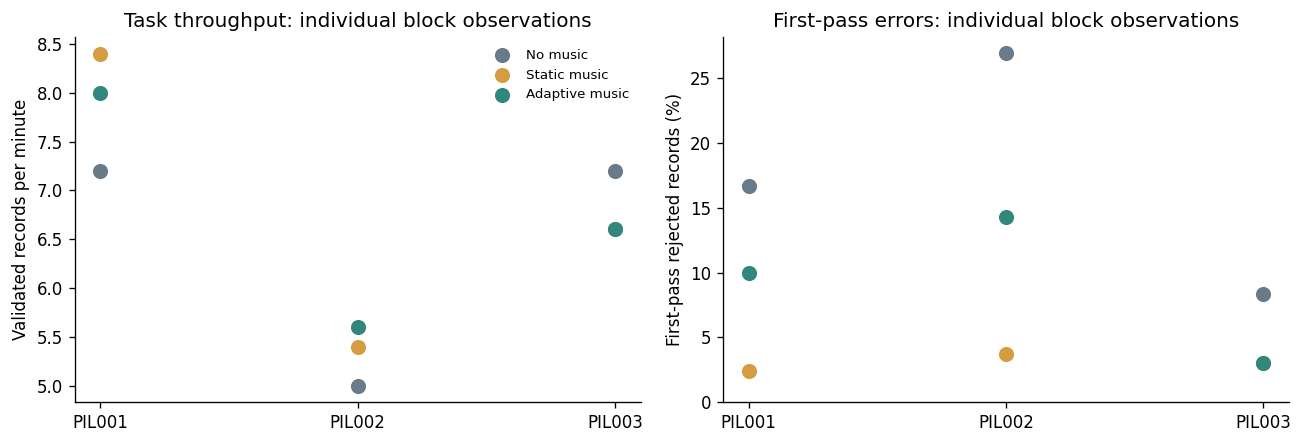

In [35]:
performance = experimental[["participant_id", "session_id", "form_block", "block", "condition", "duration_seconds", "validated_records", "validated_records_per_minute", "first_pass_error_rate", "correction_cycles", "median_il_ms", "median_fped_ms", "median_ttsv_ms"]].copy()
performance["median_il_s"] = performance.median_il_ms / 1000
performance["median_fped_s"] = performance.median_fped_ms / 1000
performance["corrections_per_validated"] = performance.correction_cycles / performance.validated_records.replace(0, np.nan)
display(performance[["participant_id", "form_block", "condition", "validated_records_per_minute", "first_pass_error_rate", "correction_cycles", "corrections_per_validated", "median_il_s", "median_fped_s"]].sort_values(["participant_id", "form_block"]))

rejected_fields = []
for bundle in bundles:
    session = bundle["session"]
    for (block, record_id), events in group_events(session).items():
        events = sorted(events, key=lambda event: event["sequence"])
        submissions = [e for e in events if e["eventType"] == "record_submitted"]
        validations = [e for e in events if e["eventType"] == "validation_result"]
        successful_values = next((s.get("payload", {}).get("values") for s,v in zip(submissions, validations) if v.get("payload", {}).get("accepted") is True), None)
        for submission, validation in zip(submissions, validations):
            if validation.get("payload", {}).get("accepted") is True:
                continue
            for field in validation.get("payload", {}).get("incorrectFields", []):
                entered = submission.get("payload", {}).get("values", {}).get(field)
                expected = successful_values.get(field) if successful_values else None
                case_only = isinstance(entered, str) and isinstance(expected, str) and entered != expected and entered.casefold() == expected.casefold()
                rejected_fields.append({"participant_id": session["participantId"], "session_id": session["id"], "block": block,
                    "record_id": record_id, "field": field, "classification": "case_only" if case_only else "other_mismatch" if expected is not None else "unresolved_answer"})
field_errors = pd.DataFrame(rejected_fields)
main_field_errors = field_errors.loc[field_errors.block.ge(2)].copy()
field_summary = main_field_errors.groupby(["field", "classification"]).size().unstack(fill_value=0)
print("Experimental-block incorrect fields across all rejected submissions (a submission can have several incorrect fields)")
display(field_summary)
print("Case-only checks use a later accepted submission of the SAME record as the answer key; no historical record generator is assumed.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for condition in CONDITIONS:
    subset = performance.loc[performance.condition.eq(condition)].sort_values("participant_id")
    axes[0].scatter(subset.participant_id, subset.validated_records_per_minute, label=condition, color=COLORS[condition], s=65)
    axes[1].scatter(subset.participant_id, 100*subset.first_pass_error_rate, label=condition, color=COLORS[condition], s=65)
axes[0].set(title="Task throughput: individual block observations", ylabel="Validated records per minute")
axes[1].set(title="First-pass errors: individual block observations", ylabel="First-pass rejected records (%)")
axes[0].legend(fontsize=8, frameon=False); axes[1].set_ylim(bottom=0)
fig.tight_layout(); plt.show()

### Experimental-block record counts and historical time-to-15 comparison

“Completed” means successfully validated: correcting the same record still completes only one distinct record. Counts below exclude practice and silent calibration. Each experimental block lasted 300 seconds in these exports.

The tables report completed records by condition and block position, plus **directly observed** counts in each block's first 120 seconds and the elapsed time at which the 15th distinct record was validated. Timing is relative to the first record presentation in that block; it is not the form submission time or the participant's session clock origin.

These are main-task observations after calibration, under different auditory conditions. The time-to-15 analysis is retained as a historical comparison from the earlier proposal. The revised next-pilot protocol uses 20 completed records, justified at the end of this notebook. These main-block data cannot substitute for a measured 20-record silent calibration or demonstrate stable calibration medians.

In [36]:
main_record_rows = []
for block in experimental.sort_values(["participant_id", "form_block"]).itertuples():
    rows = raw_records.loc[raw_records.session_id.eq(block.session_id) & raw_records.block.eq(block.block)]
    origin = rows.presented_ms.min()
    valid = rows.loc[rows.validated_ms.notna()].sort_values("validated_ms")
    submitted = rows.loc[rows.first_submission_ms.notna()]
    observed_completed = len(valid)
    assert observed_completed == block.validated_records, "Main-block completed count disagrees with CSV."
    main_record_rows.append({
        "participant_id": block.participant_id, "session_id": block.session_id,
        "form_block": block.form_block, "exported_block": block.block, "condition": str(block.condition),
        "duration_seconds": block.duration_seconds,
        "records_presented": len(rows), "records_submitted": len(submitted),
        "records_completed": observed_completed,
        "completed_per_minute": observed_completed/(block.duration_seconds/60),
        "completed_in_first_120s": int(valid.validated_ms.le(origin+120_000).sum()),
        "seconds_to_15_completed": (valid.iloc[14].validated_ms-origin)/1000 if len(valid) >= 15 else np.nan,
        "presented_not_completed": len(rows)-observed_completed,
    })
main_record_counts = pd.DataFrame(main_record_rows)
print("Each five-minute experimental block (main blocks only)")
display(main_record_counts.drop(columns="session_id"))
print("Completed records by condition")
main_counts_by_condition = main_record_counts.pivot(index="participant_id", columns="condition", values="records_completed").reindex(columns=CONDITIONS)
main_counts_by_condition["total_main_records"] = main_counts_by_condition.sum(axis=1)
display(main_counts_by_condition)
print("Completed records by experimental position; condition order differs across participants")
display(main_record_counts.pivot(index="participant_id", columns="form_block", values="records_completed").rename(columns={1:"Block 1",2:"Block 2",3:"Block 3"}))

baseline_by_participant = completed.loc[completed.block.eq(1)].set_index("participant_id").validated_records
main_two_minute_comparison = main_record_counts.groupby("participant_id").agg(
    main_first_120s_min=("completed_in_first_120s", "min"),
    main_first_120s_max=("completed_in_first_120s", "max"),
    main_time_to_15_min_s=("seconds_to_15_completed", "min"),
    main_time_to_15_max_s=("seconds_to_15_completed", "max"),
)
main_two_minute_comparison.insert(0,"silent_baseline_completed_in_120s",baseline_by_participant)
print("Silent-baseline counts versus directly observed early-main-block completion")
display(main_two_minute_comparison)
print("Main-block totals and time-to-15 range")
display(pd.DataFrame([{
    "experimental_blocks": len(main_record_counts),
    "total_records_completed": int(main_record_counts.records_completed.sum()),
    "completed_per_block_min": int(main_record_counts.records_completed.min()),
    "completed_per_block_max": int(main_record_counts.records_completed.max()),
    "time_to_15_min_s": main_record_counts.seconds_to_15_completed.min(),
    "time_to_15_median_s": main_record_counts.seconds_to_15_completed.median(),
    "time_to_15_max_s": main_record_counts.seconds_to_15_completed.max(),
}]))

Each five-minute experimental block (main blocks only)


,participant_id,form_block,exported_block,condition,duration_seconds,records_presented,records_submitted,records_completed,completed_per_minute,completed_in_first_120s,seconds_to_15_completed,presented_not_completed
0,PIL001,1,2,No music,300,37,36,36,7.200,14,120.041,1
1,PIL001,2,3,Static music,300,43,42,42,8.400,16,112.596,1
2,PIL001,3,4,Adaptive music,300,41,40,40,8.000,15,115.468,1
3,PIL002,1,2,Static music,300,28,27,27,5.400,11,162.324,1
4,PIL002,2,3,Adaptive music,300,29,28,28,5.600,11,161.398,1
5,PIL002,3,4,No music,300,26,26,25,5.000,11,172.931,1
6,PIL003,1,2,Adaptive music,300,34,33,33,6.600,12,141.237,1
7,PIL003,2,3,No music,300,37,36,36,7.200,15,119.515,1
8,PIL003,3,4,Static music,300,34,33,33,6.600,13,133.980,1


Completed records by condition


condition,No music,Static music,Adaptive music,total_main_records
participant_id,,,,
PIL001,36,42,40,118
PIL002,25,27,28,80
PIL003,36,33,33,102


Completed records by experimental position; condition order differs across participants


form_block,Block 1,Block 2,Block 3
participant_id,,,
PIL001,36,42,40
PIL002,27,28,25
PIL003,33,36,33


Silent-baseline counts versus directly observed early-main-block completion


,silent_baseline_completed_in_120s,main_first_120s_min,main_first_120s_max,main_time_to_15_min_s,main_time_to_15_max_s
participant_id,,,,,
PIL001,18,14,16,112.596,120.041
PIL002,11,11,11,161.398,172.931
PIL003,12,12,15,119.515,141.237


Main-block totals and time-to-15 range


,experimental_blocks,total_records_completed,completed_per_block_min,completed_per_block_max,time_to_15_min_s,time_to_15_median_s,time_to_15_max_s
0,9,300,25,42,112.596,133.980,172.931


### Directly observed time to 20 completed records

The following calculation measures the interval from each main block's first record presentation to acceptance of its 20th distinct record, including correction time. It reads the archived CSV timings directly; it does not scale average throughput. Practice and silent baseline are excluded. The original silent baselines stopped at 120 seconds with fewer than 20 completed records.


In [ ]:
# Direct observed time to the 20th distinct accepted record (no throughput extrapolation).
import csv, io, zipfile, statistics
from pathlib import Path

pilot_archive = next(parent / "feedback-files/results/pilot-study-v1.zip"
                     for parent in [Path.cwd(), *Path.cwd().parents]
                     if (parent / "feedback-files/results/pilot-study-v1.zip").exists())
time_to_20_rows = []
with zipfile.ZipFile(pilot_archive) as outer:
    for name in outer.namelist():
        if not name.endswith(".zip") or name.startswith("__MACOSX"):
            continue
        with zipfile.ZipFile(io.BytesIO(outer.read(name))) as bundle:
            records = list(csv.DictReader(io.StringIO(bundle.read("records.csv").decode("utf-8-sig"))))
            blocks = list(csv.DictReader(io.StringIO(bundle.read("blocks.csv").decode("utf-8-sig"))))
            for block in blocks:
                number = int(block["block"])
                if number < 2:  # Exclude practice and historical silent calibration.
                    continue
                rows = [row for row in records if int(row["block"]) == number]
                accepted = {row["record_id"]: row for row in rows if row["validated_ms"] not in ("", "null")}
                valid = sorted(accepted.values(), key=lambda row: float(row["validated_ms"]))
                if len(valid) < 20:
                    continue
                origin = min(float(row["presented_ms"]) for row in rows if row["presented_ms"] not in ("", "null"))
                seconds = (float(valid[19]["validated_ms"]) - origin) / 1000
                assert seconds >= 0
                time_to_20_rows.append({"participant": rows[0]["participant_id"], "main_block": number - 1,
                                        "condition": block["condition"], "seconds": seconds})
time_to_20_rows.sort(key=lambda row: (row["participant"], row["main_block"]))
print("Participant | Main block | Condition | Seconds to 20 completed")
for row in time_to_20_rows:
    print(f"{row['participant']} | {row['main_block']} | {row['condition']} | {row['seconds']:.3f}")
print("\nParticipant | Median seconds | Minimum | Maximum")
for participant in sorted({row["participant"] for row in time_to_20_rows}):
    values = [row["seconds"] for row in time_to_20_rows if row["participant"] == participant]
    print(f"{participant} | {statistics.median(values):.3f} | {min(values):.3f} | {max(values):.3f}")
time_to_20_values = [row["seconds"] for row in time_to_20_rows]
print(f"\nAcross {len(time_to_20_values)} main blocks: median {statistics.median(time_to_20_values):.3f} s; "
      f"mean {statistics.mean(time_to_20_values):.3f} s; range {min(time_to_20_values):.3f}–{max(time_to_20_values):.3f} s.")
print("Repeated observations from three participants; these are not measured silent-calibration durations.")


Participant | Main block | Condition | Seconds to 20 completed
PIL001 | 1 | No music | 157.024
PIL001 | 2 | Static music | 146.223
PIL001 | 3 | Adaptive music | 151.033
PIL002 | 1 | Static music | 218.967
PIL002 | 2 | Adaptive music | 211.502
PIL002 | 3 | No music | 232.927
PIL003 | 1 | Adaptive music | 183.008
PIL003 | 2 | No music | 160.709
PIL003 | 3 | Static music | 178.245

Participant | Median seconds | Minimum | Maximum
PIL001 | 151.033 | 146.223 | 157.024
PIL002 | 218.967 | 211.502 | 232.927
PIL003 | 178.245 | 160.709 | 183.008

Across 9 main blocks: median 178.245 s; mean 182.182 s; range 146.223–232.927 s.
Repeated observations from three participants; these are not measured silent-calibration durations.


## 4. Silent baseline calibration: record counts and results

This section describes **exported block 1**, the two-minute silent baseline calibration. It is separate from practice (block 0) and the experimental No Music condition (block 2, 3, or 4 depending on condition order).

- **Presented:** records shown, including a final unfinished record when time expires.
- **First submitted:** distinct records with at least one submission, not the number of submission attempts.
- **Validated:** records eventually accepted, including corrected records.
- **First-pass correct / rejected:** whether the first submission of a record was accepted or rejected. A later correction does not turn a first-pass rejection into a first-pass success.
- **Correction cycles:** additional submission attempts after the first.
- **Reference IL / FPED:** participant-specific median initiation latency and first-pass entry duration used as adaptive timing references. Their sample sizes are shown explicitly.

Totals below pool counts only. They do not replace individual calibration references with a pooled timing median, and do not establish a required minimum baseline sample size.

In [37]:
calibration = completed.loc[completed.block.eq(1)].copy().sort_values("participant_id")
assert not calibration.duplicated("session_id").any(), "More than one completed baseline per session: inspect attempts."
baseline_rows = []
for baseline in calibration.itertuples():
    rows = raw_records.loc[raw_records.session_id.eq(baseline.session_id) & raw_records.block.eq(1)]
    submitted = rows.loc[rows.first_submission_ms.notna()]
    judged = submitted.loc[submitted.first_pass_rejected.notna()]
    validated = rows.loc[rows.validated_ms.notna()]
    baseline_rows.append({
        "participant_id": baseline.participant_id, "session_id": baseline.session_id,
        "duration_seconds": baseline.duration_seconds,
        "records_presented": len(rows), "first_submitted_records": len(submitted),
        "validated_records": len(validated), "presented_not_submitted": int(rows.first_submission_ms.isna().sum()),
        "submitted_not_validated": int(submitted.validated_ms.isna().sum()),
        "first_pass_correct": int(judged.first_pass_rejected.eq(False).sum()),
        "first_pass_rejected_records": int(judged.first_pass_rejected.eq(True).sum()),
        "correction_cycles": int(rows.submission_count.sub(1).clip(lower=0).sum()),
        "il_reference_records": int(submitted.il_ms.notna().sum()),
        "fped_reference_records": int(submitted.fped_ms.notna().sum()),
    })
baseline_counts = pd.DataFrame(baseline_rows).sort_values("participant_id")
# Keep the variable used by the recommendations section compatible with the richer table.
calibration["first_submitted_records"] = calibration.session_id.map(baseline_counts.set_index("session_id").first_submitted_records)
print("Baseline record counts (one row per participant)")
display(baseline_counts.drop(columns="session_id"))

baseline_results = calibration[["participant_id", "validated_records_per_minute", "first_pass_error_rate", "first_pass_accuracy", "median_il_ms", "median_fped_ms", "median_ttsv_ms", "correction_cycles_per_validated_record"]].copy()
baseline_results["first_pass_error_percent"] = 100*baseline_results.first_pass_error_rate
baseline_results["first_pass_accuracy_percent"] = 100*baseline_results.first_pass_accuracy
baseline_results["reference_il_seconds"] = baseline_results.median_il_ms/1000
baseline_results["reference_fped_seconds"] = baseline_results.median_fped_ms/1000
baseline_results["median_validation_time_seconds"] = baseline_results.median_ttsv_ms/1000
print("Baseline performance and participant-specific timing references")
display(baseline_results[["participant_id", "validated_records_per_minute", "first_pass_error_percent", "first_pass_accuracy_percent", "reference_il_seconds", "reference_fped_seconds", "median_validation_time_seconds", "correction_cycles_per_validated_record"]])

count_columns = ["records_presented", "first_submitted_records", "validated_records", "presented_not_submitted", "submitted_not_validated", "first_pass_correct", "first_pass_rejected_records", "correction_cycles"]
baseline_totals = baseline_counts[count_columns].sum().astype(int)
total_baseline_minutes = baseline_counts.duration_seconds.sum()/60
baseline_overview = pd.DataFrame([{
    "participants": len(calibration), "total_baseline_minutes": total_baseline_minutes,
    **baseline_totals.to_dict(),
    "pooled_validated_records_per_minute": baseline_totals.validated_records/total_baseline_minutes,
    "pooled_first_pass_accuracy_percent": 100*baseline_totals.first_pass_correct/(baseline_totals.first_pass_correct+baseline_totals.first_pass_rejected_records),
}])
print("Combined baseline counts and rates; pooled rates are ratios of totals, not averages of participant percentages")
display(baseline_overview)

Baseline record counts (one row per participant)


,participant_id,duration_seconds,records_presented,first_submitted_records,validated_records,presented_not_submitted,submitted_not_validated,first_pass_correct,first_pass_rejected_records,correction_cycles,il_reference_records,fped_reference_records
0,PIL001,120,19,18,18,1,0,18,0,0,18,18
1,PIL002,120,12,11,11,1,0,9,2,2,11,11
2,PIL003,120,13,12,12,1,0,12,0,0,12,12


Baseline performance and participant-specific timing references


,participant_id,validated_records_per_minute,first_pass_error_percent,first_pass_accuracy_percent,reference_il_seconds,reference_fped_seconds,median_validation_time_seconds,correction_cycles_per_validated_record
6,PIL001,9.000,0.000,100.000,0.746,5.515,6.246,0.000
11,PIL002,5.500,18.182,81.818,1.021,7.775,9.050,0.182
1,PIL003,6.000,0.000,100.000,1.148,7.650,8.766,0.000


Combined baseline counts and rates; pooled rates are ratios of totals, not averages of participant percentages


,participants,total_baseline_minutes,records_presented,first_submitted_records,validated_records,presented_not_submitted,submitted_not_validated,first_pass_correct,first_pass_rejected_records,correction_cycles,pooled_validated_records_per_minute,pooled_first_pass_accuracy_percent
0,3,6.000,44,41,41,3,0,39,2,2,6.833,95.122


### Block-boundary and adaptive scheduling checks

Configured duration and wall-clock duration are separate checks. Decision timing is measured relative to the first presentation in the relevant block. The baseline results above remain distinct from the experimental-block scheduling checks below.

In [38]:
block_meta = pd.DataFrame([{**block, "session_id": b["session"]["id"], "participant_id": b["session"]["participantId"]} for b in bundles for block in b["session"]["blocks"]])
block_meta["started_utc"] = pd.to_datetime(block_meta.startedAt, utc=True)
block_meta["ended_utc"] = pd.to_datetime(block_meta.endedAt, utc=True)
block_meta["wall_duration_s"] = (block_meta.ended_utc-block_meta.started_utc).dt.total_seconds()
block_meta["wall_minus_configured_s"] = block_meta.wall_duration_s - block_meta.durationSeconds
print("Wall-clock duration minus saved block duration (seconds)")
display(block_meta.groupby("participant_id").wall_minus_configured_s.agg(["min", "max"]))

first_presentations = raw_records.groupby(["session_id", "block"], as_index=False).presented_ms.min().rename(columns={"presented_ms": "block_origin_ms"})
decision_audit = decisions.merge(first_presentations, on=["session_id", "block"], validate="many_to_one").merge(
    experimental[["session_id", "block", "duration_seconds"]], on=["session_id", "block"], validate="many_to_one")
decision_audit["elapsed_s"] = (decision_audit.window_end_ms-decision_audit.block_origin_ms)/1000
# Evaluations at or after the nominal block duration cannot provide meaningful in-block exposure.
decision_audit["at_or_after_end"] = decision_audit.elapsed_s.ge(decision_audit.duration_seconds)
decision_audit["waiting"] = decision_audit.reason.fillna("").str.contains("waiting", case=False)
# Legacy exports do not freeze the full adaptive config. Infer waiting from the recorded reason,
# not the current minimumRecordCount setting.
decision_audit["actionable"] = ~decision_audit.at_or_after_end
cadence = decision_audit.groupby("participant_id").agg(total_evaluations=("block", "size"),
    in_block_evaluations=("actionable", "sum"), terminal_evaluations=("at_or_after_end", "sum"),
    waiting_evaluations=("waiting", "sum"), first_evaluation_s=("elapsed_s", "min"), last_evaluation_s=("elapsed_s", "max"))
display(cadence)
display(decision_audit.loc[decision_audit.at_or_after_end, ["participant_id", "elapsed_s", "record_count", "previous_state", "selected_state", "reason"]])

Wall-clock duration minus saved block duration (seconds)


,min,max
participant_id,,
PIL001,0.025,0.072
PIL002,0.027,0.067
PIL003,0.024,0.072


,total_evaluations,in_block_evaluations,terminal_evaluations,waiting_evaluations,first_evaluation_s,last_evaluation_s
participant_id,,,,,,
PIL001,8,8,0,0,60.014,270.018
PIL002,9,8,1,0,60.003,300.012
PIL003,9,8,1,0,60.007,300.011


,participant_id,elapsed_s,record_count,previous_state,selected_state,reason
8,PIL003,300.011,7,elevated,elevated,Recent performance met every elevated-state tr...
25,PIL002,300.012,6,reduced,reduced,Recent performance met a reduced-state trigger.


## 5. Adaptive decisions and crossfade verification

A retained state is not a transition. Examine actual track-ID changes and their matching browser transition outcomes. Report final-boundary evaluations separately. Do not relax thresholds just because one participant never reaches Elevated: state labels are music-selection categories, not measured psychological states.

selected_state,baseline,reduced,elevated,silent
participant_id,,,,
PIL001,6,2,0,0
PIL002,3,5,0,0
PIL003,5,1,2,0


,transitions,successful,minimum_ms,maximum_ms,mean_deviation_ms
participant_id,,,,,
PIL001,3,3,"5,022.400","5,023.200",22.900
PIL002,5,5,"5,017.800","5,039.400",26.240
PIL003,5,5,"5,019.200","5,046.600",32.940


Track-changing decisions without a transition: 0
Transition rows without a matching track-changing decision: 0
Duplicate decision IDs within sessions: 0


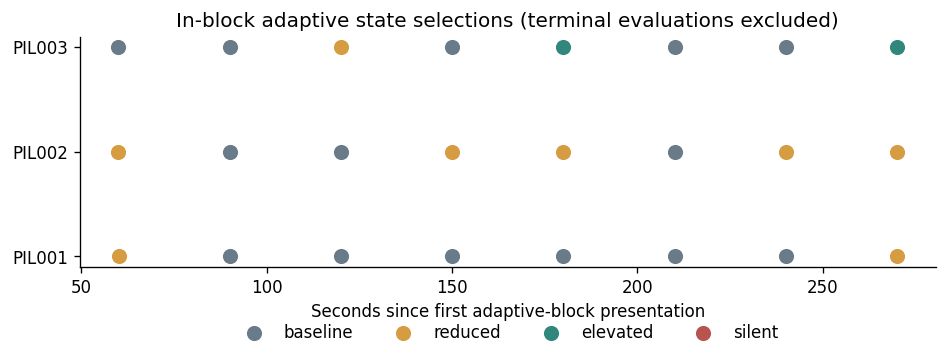

Successful timing logs confirm reported playback completion, not perceived smoothness or headphone comfort; ask participants about those separately.


In [39]:
in_block_decisions = decision_audit.loc[decision_audit.actionable].copy()
state_counts = in_block_decisions.groupby(["participant_id", "selected_state"]).size().unstack(fill_value=0).reindex(columns=["baseline", "reduced", "elevated", "silent"], fill_value=0)
display(state_counts)

decision_details = pd.DataFrame([{**d, "session_id": b["session"]["id"], "participant_id": b["session"]["participantId"]} for b in bundles for d in b["session"].get("musicDecisions", [])])
expected_changes = decision_details.loc[decision_details.previousTrackId.fillna("<silent>").ne(decision_details.selectedTrackId.fillna("<silent>"))].copy()
actual_transitions = pd.DataFrame([{**t, "session_id": b["session"]["id"]} for b in bundles for t in b["session"].get("musicTransitions", [])])
transition_match = expected_changes.merge(actual_transitions, left_on=["session_id", "id"], right_on=["session_id", "decisionId"], how="outer", indicator=True, suffixes=("_decision", "_transition"), validate="one_to_one")
transitions["observed_crossfade_ms"] = transitions.completed_ms - transitions.started_ms
transitions["deviation_ms"] = transitions.observed_crossfade_ms - transitions.configured_crossfade_ms
transition_summary = transitions.groupby("participant_id").agg(transitions=("block", "size"),
    successful=("outcome", lambda values: values.eq("playing").sum()),
    minimum_ms=("observed_crossfade_ms", "min"), maximum_ms=("observed_crossfade_ms", "max"),
    mean_deviation_ms=("deviation_ms", "mean"))
display(transition_summary)
print("Track-changing decisions without a transition:", int(transition_match._merge.eq("left_only").sum()))
print("Transition rows without a matching track-changing decision:", int(transition_match._merge.eq("right_only").sum()))
print("Duplicate decision IDs within sessions:", int(decision_details.duplicated(["session_id", "id"]).sum()))

fig, ax = plt.subplots(figsize=(8, 3.2))
for row_index, (participant, group) in enumerate(in_block_decisions.groupby("participant_id")):
    for state, color in [("baseline", "#697a89"), ("reduced", "#d69c42"), ("elevated", "#31877b"), ("silent", "#b85450")]:
        subset = group.loc[group.selected_state.eq(state)]
        ax.scatter(subset.elapsed_s, [row_index]*len(subset), color=color, s=65, label=state if row_index == 0 else None)
ax.set(yticks=range(len(state_counts)), yticklabels=sorted(state_counts.index), xlabel="Seconds since first adaptive-block presentation", title="In-block adaptive state selections (terminal evaluations excluded)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18)); fig.tight_layout(); plt.show()
print("Successful timing logs confirm reported playback completion, not perceived smoothness or headphone comfort; ask participants about those separately.")

## 6. Link and score the PFS responses descriptively

The supplied thesis, Appendix E.1, defines nine positively worded 1–7 items: absorption (items 1–3), effortless control (4–6), and intrinsic reward (7–9). Each dimension is the mean of its three items; the overall item mean is retained for completeness. No missing-item imputation or reverse scoring is applied. This notebook does not test flow efficacy or treat the PFS as a dedicated usability scale.

Items are selected by explicit column wording, not by assuming all numeric columns are questionnaire items. Block mapping is checked against each session's assigned condition order, rather than using a fixed condition-to-block mapping.

In [40]:
PFS_ITEMS = [
    "I was absorbed in the task", "I was highly focused on the task", "All my attention was on the task",
    "I felt like I could easily control what I was doing", "My actions flowed effortlessly", "There was a sense of fluidity to my actions",
    "I found the experience rewarding", "The experience felt satisfying", "I would like the feeling of that experience again",
]
pfs_raw = pd.read_csv(PFS_CSV)
assert set(["Timestamp", "Participant Code", "Block Number", *PFS_ITEMS]).issubset(pfs_raw.columns), "Unexpected PFS form columns."
pfs = pfs_raw.rename(columns={"Participant Code": "participant_id", "Block Number": "form_block"}).copy()
pfs["participant_id"] = pfs.participant_id.astype(str).str.strip().str.upper()
pfs["form_block"] = pd.to_numeric(pfs.form_block, errors="coerce")
pfs["form_row"] = np.arange(2, len(pfs)+2)  # CSV row number, including its header
for item in PFS_ITEMS:
    pfs[item] = pd.to_numeric(pfs[item], errors="coerce")
pfs["missing_items"] = pfs[PFS_ITEMS].isna().sum(axis=1)
pfs["invalid_items"] = ((pfs[PFS_ITEMS].lt(1) | pfs[PFS_ITEMS].gt(7) | pfs[PFS_ITEMS].mod(1).ne(0)) & pfs[PFS_ITEMS].notna()).sum(axis=1)
pfs["valid_items"] = pfs.missing_items.eq(0) & pfs.invalid_items.eq(0)
pfs["absorption"] = pfs[PFS_ITEMS[:3]].mean(axis=1).where(pfs.valid_items)
pfs["effortless_control"] = pfs[PFS_ITEMS[3:6]].mean(axis=1).where(pfs.valid_items)
pfs["intrinsic_reward"] = pfs[PFS_ITEMS[6:9]].mean(axis=1).where(pfs.valid_items)
pfs["overall_item_mean"] = pfs[PFS_ITEMS].mean(axis=1).where(pfs.valid_items)

expected_keys = experimental[["participant_id", "session_id", "form_block", "block", "condition"]].copy()
expected_keys["participant_id"] = expected_keys.participant_id.str.strip().str.upper()
assert not expected_keys.duplicated(["participant_id", "form_block"]).any(), "Repeated sessions need an explicit session ID in the form."
pfs_duplicates = pfs.loc[pfs.duplicated(["participant_id", "form_block"], keep=False)]
if not pfs_duplicates.empty:
    display(pfs_duplicates[["form_row", "participant_id", "form_block"]])
    raise ValueError("Duplicate form keys: explicitly resolve responses rather than selecting the latest automatically.")
link_audit = expected_keys.merge(pfs[["participant_id", "form_block"]], on=["participant_id", "form_block"], how="outer", indicator=True, validate="one_to_one")
print("Missing form responses:", int(link_audit._merge.eq("left_only").sum()), "Unmatched form responses:", int(link_audit._merge.eq("right_only").sum()))
print("Invalid/missing item rows:", int((~pfs.valid_items).sum()))
joined = expected_keys.merge(pfs, on=["participant_id", "form_block"], how="left", validate="one_to_one")
joined = joined.merge(performance.drop(columns=["participant_id", "form_block", "condition"]), on=["session_id", "block"], validate="one_to_one")
display(joined[["participant_id", "form_block", "condition", "absorption", "effortless_control", "intrinsic_reward", "overall_item_mean"]].sort_values(["participant_id", "form_block"]))

Missing form responses: 0 Unmatched form responses: 0
Invalid/missing item rows: 0


,participant_id,form_block,condition,absorption,effortless_control,intrinsic_reward,overall_item_mean
3,PIL001,1,No music,5.333,5.333,2.667,4.444
4,PIL001,2,Static music,5.000,6.333,3.667,5.000
5,PIL001,3,Adaptive music,5.000,6.000,2.333,4.444
6,PIL002,1,Static music,6.333,6.667,4.667,5.889
7,PIL002,2,Adaptive music,5.667,5.333,4.333,5.111
8,PIL002,3,No music,4.000,3.333,1.667,3.000
0,PIL003,1,Adaptive music,6.000,6.000,5.333,5.778
1,PIL003,2,No music,5.667,5.333,3.333,4.778
2,PIL003,3,Static music,4.667,5.333,6.333,5.444


## 7. Questionnaire timing and handover audit

Form timestamps are interpreted as **Asia/Manila local time** (the study location); exported block timestamps are UTC. Confirm that this was the Google Form's configured time zone before treating the timing flags as final.

Check whether each form submission falls between the relevant block's end and the next experimental block's start. Submission time is not necessarily answer time: researcher transcription, offline collection, or delayed entry can explain a flag. Preserve flagged responses and confirm the collection method rather than silently excluding them.

In [41]:
FORM_TIMEZONE = "Asia/Manila"
joined["form_time"] = pd.to_datetime(joined.Timestamp, format="%m/%d/%Y %H:%M:%S", errors="coerce").dt.tz_localize(FORM_TIMEZONE)
ends = block_meta.loc[block_meta.number.ge(2), ["session_id", "number", "started_utc", "ended_utc"]].rename(columns={"number": "block"}).copy()
ends = ends.sort_values(["session_id", "block"])
ends["next_block_start_utc"] = ends.groupby("session_id").started_utc.shift(-1)
joined = joined.merge(ends, on=["session_id", "block"], validate="one_to_one")
joined["form_time_utc"] = joined.form_time.dt.tz_convert("UTC")
joined["minutes_after_block_end"] = (joined.form_time_utc-joined.ended_utc).dt.total_seconds()/60
joined["before_block_end"] = joined.form_time_utc.lt(joined.ended_utc)
joined["after_next_block_start"] = joined.next_block_start_utc.notna() & joined.form_time_utc.ge(joined.next_block_start_utc)
joined = joined.sort_values(["participant_id", "form_block"])
joined["seconds_since_previous_form"] = joined.groupby("participant_id").form_time.diff().dt.total_seconds()
clustered_ids = set(joined.loc[joined.seconds_since_previous_form.between(0, 10), "participant_id"])
joined["clustered_submission"] = joined.participant_id.isin(clustered_ids)
joined["timing_review"] = joined.before_block_end | joined.after_next_block_start | joined.clustered_submission | joined.form_time.isna()
print("The <=10-second clustering flag is a workflow diagnostic, not a validated response-exclusion rule.")
display(joined[["participant_id", "form_block", "condition", "form_time", "minutes_after_block_end", "seconds_since_previous_form", "after_next_block_start", "clustered_submission", "timing_review"]])
print("Flagged participants:", ", ".join(sorted(joined.loc[joined.timing_review, "participant_id"].unique())) or "None")

The <=10-second clustering flag is a workflow diagnostic, not a validated response-exclusion rule.


,participant_id,form_block,condition,form_time,minutes_after_block_end,seconds_since_previous_form,after_next_block_start,clustered_submission,timing_review
3,PIL001,1,No music,2026-10-17 18:27:34+08:00,2.322,NaN,False,False,False
4,PIL001,2,Static music,2026-10-17 18:36:42+08:00,2.360,548.000,False,False,False
5,PIL001,3,Adaptive music,2026-10-17 18:44:41+08:00,0.890,479.000,False,False,False
6,PIL002,1,Static music,2026-10-17 20:32:37+08:00,0.898,NaN,False,False,False
7,PIL002,2,Adaptive music,2026-10-17 20:39:35+08:00,1.141,418.000,False,False,False
8,PIL002,3,No music,2026-10-17 20:45:36+08:00,0.770,361.000,False,False,False
0,PIL003,1,Adaptive music,2026-10-17 19:51:17+08:00,26.239,NaN,True,True,True
1,PIL003,2,No music,2026-10-17 19:51:20+08:00,18.096,3.000,True,True,True
2,PIL003,3,Static music,2026-10-17 19:51:23+08:00,11.594,3.000,False,True,True


Flagged participants: PIL003


## 8. PFS item patterns as follow-up usability questions

Low reward or ease ratings can motivate questions about repetition, task purpose, fatigue, or distraction; they do not identify which app feature caused a rating. Retain individual responses and questionnaire timing flags rather than presenting a condition winner. The sensitivity table below merely shows the effect of setting timing-review rows aside pending clarification.

,item,n_valid,mean,median,responses_1_to_3
0,I was absorbed in the task,9,5.556,6.000,1
1,I was highly focused on the task,9,5.556,6.000,1
2,All my attention was on the task,9,4.778,5.000,2
3,I felt like I could easily control what I was ...,9,5.778,6.000,0
4,My actions flowed effortlessly,9,5.444,6.000,1
5,There was a sense of fluidity to my actions,9,5.333,6.000,1
6,I found the experience rewarding,9,3.000,2.000,7
7,The experience felt satisfying,9,4.222,4.000,4
8,I would like the feeling of that experience again,9,4.222,5.000,4


,scope,dimension,n_forms,n_participants,mean,median
0,All linked responses,absorption,9,3,5.296,5.333
1,All linked responses,effortless_control,9,3,5.519,5.333
2,All linked responses,intrinsic_reward,9,3,3.815,3.667
3,Timing-review rows set aside (sensitivity only),absorption,6,2,5.222,5.167
4,Timing-review rows set aside (sensitivity only),effortless_control,6,2,5.500,5.667
5,Timing-review rows set aside (sensitivity only),intrinsic_reward,6,2,3.222,3.167


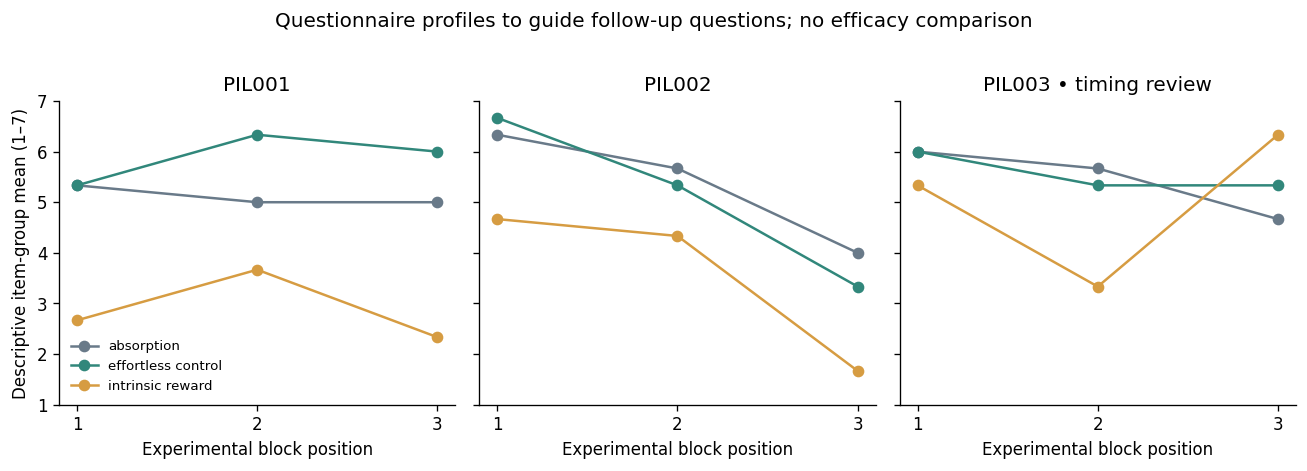

In [42]:
item_summary = pd.DataFrame({"item": PFS_ITEMS, "n_valid": [pfs.loc[pfs.valid_items, item].count() for item in PFS_ITEMS],
    "mean": [pfs.loc[pfs.valid_items, item].mean() for item in PFS_ITEMS],
    "median": [pfs.loc[pfs.valid_items, item].median() for item in PFS_ITEMS],
    "responses_1_to_3": [pfs.loc[pfs.valid_items, item].le(3).sum() for item in PFS_ITEMS]})
display(item_summary)
dimensions = ["absorption", "effortless_control", "intrinsic_reward"]
sensitivity = []
for label, subset in [("All linked responses", joined), ("Timing-review rows set aside (sensitivity only)", joined.loc[~joined.timing_review])]:
    for dimension in dimensions:
        sensitivity.append({"scope": label, "dimension": dimension, "n_forms": subset[dimension].count(),
            "n_participants": subset.loc[subset[dimension].notna(), "participant_id"].nunique(), "mean": subset[dimension].mean(), "median": subset[dimension].median()})
display(pd.DataFrame(sensitivity))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (pid, subset) in zip(axes, joined.groupby("participant_id")):
    values = subset.set_index("form_block")[dimensions]
    for dimension, color in zip(dimensions, ["#697a89", "#31877b", "#d69c42"]):
        ax.plot(values.index, values[dimension], marker="o", color=color, label=dimension.replace("_", " "))
    ax.set(title=pid + (" • timing review" if subset.timing_review.any() else ""), xticks=[1,2,3], xlabel="Experimental block position", ylim=(1,7))
axes[0].set_ylabel("Descriptive item-group mean (1–7)")
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle("Questionnaire profiles to guide follow-up questions; no efficacy comparison", y=1.02)
fig.tight_layout(); plt.show()

# Pilot Study v1: app-improvement summary

Scope: 3 participants, 9 completed experimental blocks, 9 PFS responses; historical build pilot-1.0.1. All reported pilot results used the original two-minute silent baseline. The revised 20-record protocol is a subsequent app/protocol change and has not been evaluated by these exports.

## Main findings

- Raw-event checks found 0 flagged sequence/pairing/timing/presentation issues; record-field mismatches: 0; block-measure mismatches: 0. These checks cover the supplied exports, not every failure mode.
- Completed experimental blocks: 9; saved durations: [300] seconds. 26 adaptive evaluations were exported; 2 were at/after the nominal duration boundary. Strictly in-block counts: {'PIL001': 8, 'PIL002': 8, 'PIL003': 8}.
- All 13 logged track transitions reported playback success, with durations 5.018–5.047 seconds. Logs do not establish subjective smoothness.
- Questionnaire timing requires clarification for PIL003. Their scores are preserved and flagged; confirm form time zone and whether researchers entered answers in a batch.
- PIL003’s form submissions were at 19:51:17, 19:51:20, and 19:51:23 on 17 October 2026 (Asia/Manila assumed), after the final block ended at 19:39:47. This can reflect delayed responses OR later researcher data entry; the files cannot distinguish them.
- No claim about support for flow, condition superiority, or statistical effectiveness is made.

## Prioritized changes

### P2: Calibration quality visibility

**Evidence:** Calibration first-submitted sample sizes: {'PIL001': 18, 'PIL002': 11, 'PIL003': 12}.

**Current revision / follow-up:** The next-pilot baseline is configured for 20 distinct successfully completed records, without a time cutoff, to standardize the number of observations available for adaptive timing references. Mode, target, and timed duration are controlled only through `config/study.json`; the two-minute alternative remains available there. Corrections count toward the same record. Log and review available IL/FPED sample sizes, missing measures, interruption status, actual duration, and reference medians. Twenty is a pragmatic target, not a proven statistical minimum.

**Retest:** Verify completion after exactly 20 accepted records and accurate correction/recovery logs. Compare cumulative IL/FPED medians at 10, 15, and 20 records, inspect first-half versus second-half performance, and replay identical main-block windows with those references to assess changes in adaptive decisions. Empty or invalid references require explicit handling; 20 completed records alone does not establish calibration quality.

### P2: Task repetition and perceived reward

**Evidence:** The 'experience rewarding' item was rated 1–3 in 7/9 valid responses; PFS is not a direct usability diagnosis.

**Change / follow-up:** Ask participants whether repetition, task purpose, correction friction or audio explains their ratings. Retain modest, block-specific completion feedback and optional practice; the later streak changes need their own retest and cannot be evaluated from these exports.

**Retest:** Collect brief comments after the questionnaire and verify that feedback is consistent across conditions and does not interrupt entry or prime the post-block ratings.

## Baseline calibration results

### Baseline results in plain language

Across 3 completed silent calibration blocks (6 total minutes), participants saw **44 records**, submitted **41 distinct records**, and successfully validated **41 records**.

- **PIL001:** 19 presented; 18 submitted; 18 validated; 18 correct on the first attempt; 0 first-pass rejections; 0 correction cycles. Reference IL **0.746 s** and FPED **5.515 s**, each based on 18/18 available records respectively.
- **PIL002:** 12 presented; 11 submitted; 11 validated; 9 correct on the first attempt; 2 first-pass rejections; 2 correction cycles. Reference IL **1.021 s** and FPED **7.775 s**, each based on 11/11 available records respectively.
- **PIL003:** 13 presented; 12 submitted; 12 validated; 12 correct on the first attempt; 0 first-pass rejections; 0 correction cycles. Reference IL **1.148 s** and FPED **7.650 s**, each based on 12/12 available records respectively.

There were 3 presented-but-unsubmitted records and 0 submitted-but-unvalidated records. A final record shown at a timed cutoff is not automatically evidence of data loss.

**App implication:** retain and export the calibration counts alongside each person's reference values. The revised 20-record protocol prioritizes a consistent number of observations over a fixed duration. These three historical sessions motivate examining unequal sample counts, but do not prove that 20 is optimal, establish reference stability, or justify changing adaptive threshold multipliers.

### Observed time to 20 completed records

Across the nine main blocks, the median time from first presentation to the 20th accepted record was **178.245 s (2:58)**; the mean was **182.182 s (3:02)** and the range **146.223–232.927 s (2:26–3:53)**. Corrections are included. Participant medians were 151.033 s (PIL001), 218.967 s (PIL002), and 178.245 s (PIL003). Roughly **3–4 minutes** is a provisional scheduling allowance, not a cutoff or an established silent-baseline duration. See the reproducible calculation above and the final justification below.

**Baseline-design implication:** the revised next-pilot target is 20 successfully completed silent-baseline records, replacing the earlier 15-record proposal. Direct time-to-20 measurements provide a preliminary workload estimate, but these observations occurred after calibration and under different auditory conditions. They cannot establish the duration or stability of a 20-record silent baseline. The observed two-minute baseline counts remain 18, 11, and 12. Retest the 20-record protocol directly, record its actual duration, and evaluate reference stability and adaptive-decision sensitivity. The justification and external sources appear in the final Markdown section below.

## Limits and sources

Three participants provide a pilot diagnostic, not a causal or inferential study. There are no free-text interviews, field-level keystroke traces, PFS form-open timestamps, or immutable full historical rule settings in these supplied files. Incorrect-field classification uses later accepted values from the same record. PFS timing flags use Asia/Manila as the form time zone; confirm that assumption.

Inputs (relative to the repository): `feedback-files/results/pilot-study-v1.zip` and `feedback-files/results/pilot-study-v1-pfs.csv`. Original supplied filenames were `Pilot Study v1 Results.zip` and `Tuned In - Post-Block Form (Responses) - Form Responses 1.csv`. Source hashes are retained in the notebook. PFS grouping/scoring follows the supplied thesis Appendix E.1, without efficacy testing.

This notebook contains calculations, historical results, this summary, and the subsequent baseline-protocol justification. It does not modify the app or raw inputs. Re-running the analysis recalculates the evidence; review the narrative summary and protocol notes if inputs or app settings change. Historical pilot results must remain distinct from later app revisions.

# Baseline calibration justification: revised 20-record protocol

#### Purpose and procedure

**Protocol revision:** This section explains the subsequent design choice; it does not describe the historical pilot procedure or change its results.

The revised protocol requires **20 distinct successfully validated records**, without a time limit, in silent baseline block 1. Its purpose is to estimate each participant's usual initiation latency (IL) and first-pass entry duration (FPED) as references for adaptive music. It does not assess how many records fit into 120 seconds.

Participants should understand and practise the task before calibration, then enter records at their normal pace without music. Incorrect submissions require correction of the same record; corrections do not add completed records. Calibration ends when record 20 is accepted. Submission feedback and streak rewards are available during calibration; Practice remains excluded from streak rewards. Streaks increase only on first-pass correct records, reset after rejection, and do not increase when correcting a rejected record. Instructions and progress derive their target from the saved session configuration.

Suggested participant instruction: “Complete 20 records at your normal pace. If a record contains an error, correct it and submit it again. Corrections count toward the same record. There is no two-minute cutoff.”

#### Justification and limits

The historical two-minute silent baselines produced **18, 11, and 12 completed records** for PIL001, PIL002, and PIL003 respectively. Their adaptive references therefore used different numbers of observations. These results appear in Section 4, “Silent baseline calibration: record counts and results.”

A fixed target standardizes completed-record count and avoids ending slower participants' calibration with fewer observations. Twenty provides more observations than any of these historical baselines and more than the earlier proposed target of 15. This is the study team's practical rationale for the next pilot, not evidence that 20 is optimal or that the earlier references were necessarily inaccurate.

There is no universal sample size that guarantees a representative median. PNNL's Visual Sample Plan describes choosing a median sample size according to the desired confidence and precision [1]. This supports assessing uncertainty; **it does not recommend 20 task records**. Learning, fatigue, and dependence between successive records can also affect representativeness. More records alone do not remove these effects.

No historical silent baseline reached 20 records before its timed cutoff. Those data therefore cannot establish the duration or stability of a 20-record calibration. The nine main blocks contained 25–42 completed records each, but their later position and different auditory conditions mean they cannot substitute for a silent calibration test. The pilot involved three participants, not nine independent participants.

#### Observed time to 20 records and session planning

Direct measurement of the nine main blocks gives a **median of 178.245 seconds (2 min 58 sec)** and a **mean of 182.182 seconds (3 min 2 sec)** to the 20th completed record. The observed range is **146.223–232.927 seconds (2 min 26 sec–3 min 53 sec)**, measured from the first presentation and including correction time.

| Participant | Median across three main blocks | Observed range |
| --- | ---: | ---: |
| PIL001 | 2 min 31 sec | 2:26–2:37 |
| PIL002 | 3 min 39 sec | 3:32–3:53 |
| PIL003 | 2 min 58 sec | 2:41–3:03 |

These observations suggest **roughly 3–4 minutes as a provisional planning allowance**, not a stopping rule or an upper bound. The calibration remains record-based with no time cutoff. The nine blocks are repeated observations from three participants, and include No Music, Static Music, and Adaptive Music after calibration. Consequently, they support a preliminary workload estimate, not an established duration for the revised silent baseline or proof of stable adaptive references. Measure actual duration and reference stability in the next pilot. The reproducible time-to-20 calculation appears earlier in this notebook.

#### Relationship to the adaptive rule

The app uses baseline median IL and FPED, rather than baseline throughput, as timing references. Corrected records retain their original first-pass timings. Twenty accepted records should provide 20 observations for each measure only when the required timing events are available and valid; check the available IL and FPED sample sizes separately.

Under the current configuration:

- Reduced music is triggered when recent median IL **or** FPED is at least 120% of its baseline, or recent first-pass error rate exceeds 15%.
- Elevated music requires **both** timing medians to be at most 95% of their baselines and recent first-pass error rate to be at most 10%.
- A sufficient recent-window record count is required, and reduced-state triggers take priority. The baseline error rate is descriptive; adaptive error thresholds are fixed configuration values.

For example, baseline FPED of 6 seconds gives timing boundaries of 7.2 seconds (reduced) and 5.7 seconds (elevated); an 8-second baseline gives 9.6 and 7.6 seconds. Lower timing values mean faster performance, so a faster baseline sets a stricter elevated timing requirement. These decisions change music state, not task difficulty.

Fewer baseline observations do not inherently give a lower reference: the estimate can be uncertain in either direction. See the implementation in [measures](../../backend/src/measures.ts), [adaptive rule](../../backend/src/rule.ts), and [study configuration](../../config/study.json).

#### Configuration and existing sessions

The revised protocol is configured in `config/study.json` as follows. Restart the backend after configuration changes:

```json
"baselineSeconds": 120,
"baseline": {
  "defaultMode": "records",
  "enabledModes": ["records", "timed"],
  "recordTarget": 20
}
```

Mode, target, and timed duration are controlled only in this file. Participant setup has no baseline selector or duration override. The retained 120-second setting is inactive in record mode. To use the two-minute alternative, set `defaultMode` to `"timed"`. To disable an alternative, remove it from `enabledModes`, keeping the chosen default enabled.

New sessions snapshot the configured rule. Existing sessions keep their original target; legacy sessions without a baseline snapshot remain timed. Restarting an interrupted baseline begins a new attempt at zero toward the session's saved target, preserving the interrupted attempt in audit data.

For analysis, distinguish protocols using `baseline_mode` and `baseline_target_records`. Record-based `duration_seconds` is elapsed time from the first presentation to final acceptance. Do not rewrite historical exports or pilot results to imply they used 20 records.

#### Next-pilot validation

1. Verify 20 distinct accepted records, correction counts, valid event ordering, and available IL/FPED sample sizes.
2. Compare each participant's cumulative median IL and FPED after 10, 15, and 20 records.
3. Compare the first 10 with the last 10 to examine continued learning or slowing. Do not automatically discard early records after inspecting results.
4. Replay the same main-block windows using the 10-, 15-, and 20-record references; report how often adaptive-state decisions differ.
5. Record duration, interruptions, and participant feedback. Define an acceptable reference-change criterion before evaluating the next pilot. Twenty records is not an automatic quality guarantee.

If confidence intervals are reported, use a method appropriate for medians and consider the sequential nature of observations. NIST describes bootstrap uncertainty estimation for medians [2]; naive independent resampling does not resolve learning trends or serial dependence.

#### Suggested methods wording

“Silent baseline calibration requires 20 successfully completed records to standardize the number of observations available for estimating participant-specific median initiation latency and first-pass entry duration. Calibration duration varies with participant pace. The target is a pragmatic protocol choice informed by pilot completion counts; stability of the resulting references will be evaluated during further pilot testing.”

#### Sources

1. Pacific Northwest National Laboratory. [Visual Sample Plan: Confidence Interval on a Median Design](https://vsp.pnnl.gov/help/vsample/Design_CI_Median.htm). Accessed 27 October 2026. Supports selecting median sample sizes for specified confidence and precision, not a universal 20-record rule.
2. National Institute of Standards and Technology. [e-Handbook of Statistical Methods: Bootstrap Plot](https://itl.nist.gov/div898/handbook/eda/section3/eda334.htm). Accessed 27 October 2026. Explains bootstrap uncertainty estimation, including a median confidence-interval example.
3. Pilot Study v1 App Improvement Analysis (this notebook), silent-baseline and main-block record tables. Source for this study's observed counts.
